In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

In [4]:
T = 24 # Time periods
nb = 5 # Buses
nl = 4 # Lines
ng = 3 # Generators

In [5]:
# Generator-to-bus mapping
G = np.array([
    [1, 0, 0],
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [0, 0, 0]
])

# Line-to-bus mapping
K = np.array([
    [1, -1, 0, 0, 0],
    [1, 0, -1, 0, 0],
    [0, 0, 1, -1, 0],
    [0, 0, 0, 1, -1]
]).T

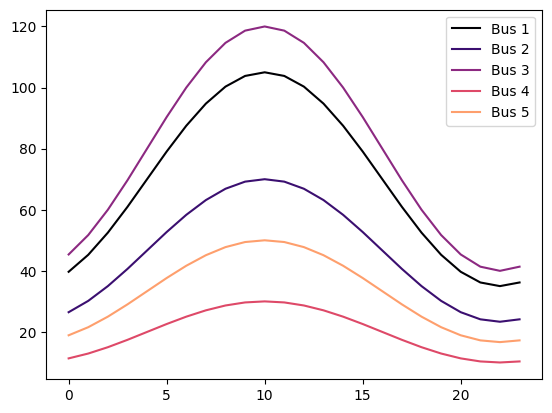

Total Peak Demand: 375 MW
Total Generation Capacity: 320 MW
Total Transmission Capacity: 325 MW
42.0
0.22000000000000003


In [144]:
# Time
time = np.arange(24)

# Load
load_shape =  (np.sin(2 * np.pi * time / T - np.pi / 3) + 2) / 3
peak_demand = np.array([105, 70, 120, 30, 50])
load = (peak_demand * load_shape.reshape(-1, 1)).T

# Plot load shapes
cmap = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [cmap(i/5) for i in range(nb)]
for i in range(nb):
    plt.plot(time, load[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.show()

# Print total peak demand
print(f"Total Peak Demand: {peak_demand.sum()} MW")

# Generation
pmax = np.array([150, 95, 75])
print(f"Total Generation Capacity: {pmax.sum()} MW")

# Lines
fmax = np.array([100, 50, 100, 75])
print(f"Total Transmission Capacity: {fmax.sum()} MW")

# VoLL Dynamics
voll = 22 # $/kWh - baseline VoLL
gamma = 0.6 # Discount rate
beta = 12 # VoLL sensitivity
print(voll + beta / gamma)
assert voll + beta / gamma > 0

# Fairness
epsilon = 0.1
print(((1 + epsilon) / nb))

# Reshape data
pmax = np.tile(pmax[:, None], (1, T))
fmax = np.tile(fmax[:, None], (1, T))

In [176]:
# CVXPY Model

# Variables
p = cp.Variable((ng, T), nonneg=True)
f = cp.Variable((nl, T))
u = cp.Variable((nb, T), nonneg=True)
z = cp.Variable((nb, T), nonneg=True)

# Parameters
v = cp.Parameter((nb, T), nonneg=True) # Static VoLL
v.value = voll * np.ones((nb, T))
x = cp.Parameter((nb, T+1), nonneg=True) # Dynamic VoLL / State
x.value = np.zeros((nb, T+1))
lam = cp.Parameter((nb, T+1)) # Costate
lam.value = np.zeros((nb, T+1))
d = cp.Parameter((nb, T), nonneg=True) # Demand
d.value = load

# Expressions
max_z = cp.max(cp.sum(z, axis=1))

# Objectives
total_ue = cp.sum(u)
ue_costs = cp.sum(cp.multiply(v, u) + cp.multiply(beta * x[:, :-1], u)) # Minimize unserved energy costs with static state variable
hamiltonian = ue_costs + cp.sum(cp.multiply(lam[:, 1:], z)) # Minimize Hamiltonian

# Constraints
constraints = [
    G @ p + K @ f == d - u,
    p <= pmax,
    f <= fmax,
    f >= -fmax,
    u == cp.multiply(d, z),
    z <= 1,
    max_z <= ((1 + epsilon) / nb) * cp.sum(z), # Fairness constraint
]

# Problem
problem = cp.Problem(cp.Minimize(total_ue), constraints)

# Solve with total unserved energy objective
min_ue = problem.solve("GUROBI")

# Add lexicographic constraint
constraints += [
    total_ue <= min_ue
]

# Define Hamiltonian problem
problem = cp.Problem(cp.Minimize(hamiltonian), constraints)

# Solve with Hamiltonian objective
min_cost = problem.solve("GUROBI")

print(min_ue)
print(min_cost)
print(H_eval())
print(J_eval(z.value))

269.76450281501354
5934.819061930298
5934.819061930298
6124.630206129819


In [177]:
def x_eval(z):
    # State trajectory eval
    x = np.zeros((nb, T+1))
    for t in range(T):
        x[:, t+1] = (1 - gamma) * x[:,t] + z[:, t]
    return x

def lam_eval(z):
    # Costate trajectory eval
    lam = np.zeros((nb, T+1))
    u = d.value * z
    for t in range(T)[::-1]:
        lam[:, t] = beta * u[:,t] + (1 - gamma) * lam[:, t+1]
    return lam

def H_eval():
    # Hamiltonian eval
    # Call this after updating lam and x parameters
    return (hamiltonian + (1 - gamma) * cp.sum(cp.multiply(lam[:, 1:], x[:, :-1]))).value

def J_eval(z):
    # Objective eval
    x = x_eval(z)
    u = d.value * z
    return np.sum((v.value + beta * x[:, :-1]) * u)

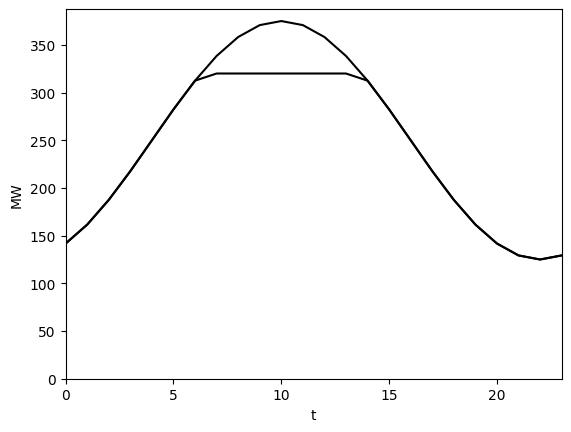

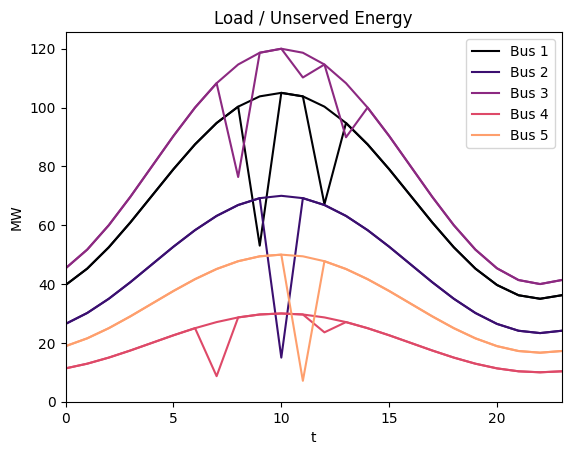

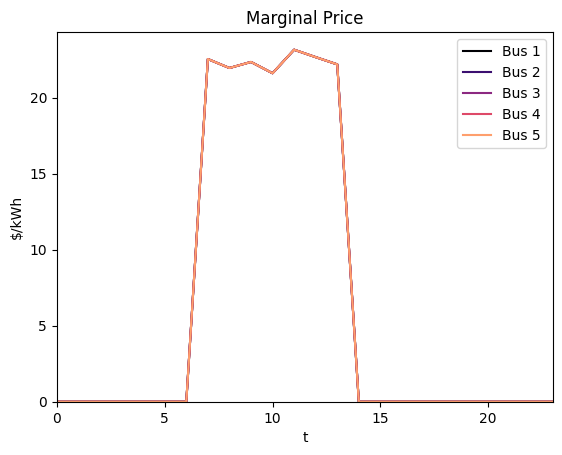

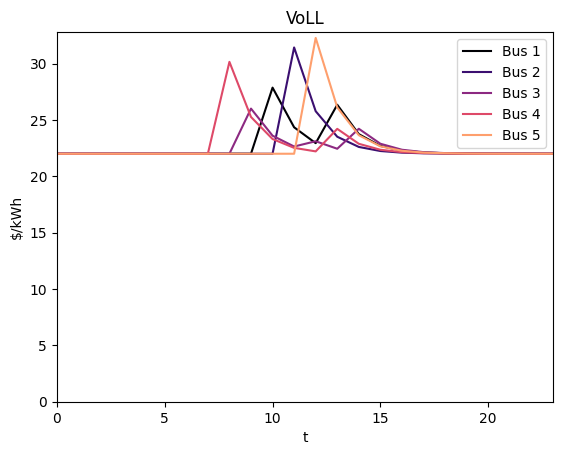

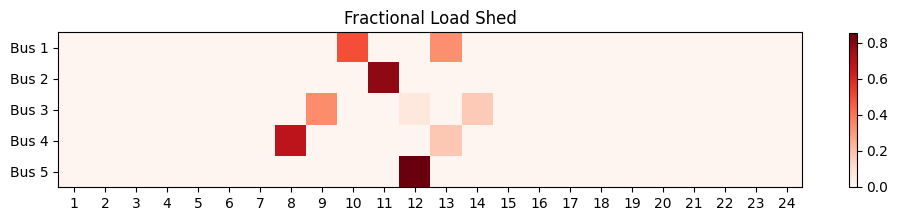

In [184]:
magma = plt.colormaps["magma"]
labels = [f"Bus {i+1}" for i in range(nb)]
colors = [magma(i/5) for i in range(nb)]

# Plot total unserved energy
plt.plot(time, np.sum(load, axis=0), color="black", label="Total")
plt.plot(time, np.sum(load - u.value, axis=0), color="black")
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot unserved energy by bus
plt.title("Load / Unserved Energy")
for i in range(nb):
    plt.plot(time, load[i, :], color=colors[i], label=labels[i])
    plt.plot(time, load[i,:] - u[i, :].value, color=colors[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("MW")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot risk by bus
lmp = -constraints[0].dual_value
plt.title("Marginal Price")
for i in range(nb):
    plt.plot(time, lmp[i, :], color=colors[i], label=labels[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("$/kWh")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot VoLL by bus
xval = x_eval(z.value)
vval = voll + beta * xval
plt.title("VoLL")
for i in range(nb):
    plt.plot(time, vval[i,:-1], color=colors[i], label=labels[i])
plt.legend()
plt.xlabel("t")
plt.ylabel("$/kWh")
plt.axis([0, T-1, 0, None])
plt.show()

# Plot load shed fractions by bus
reds = plt.colormaps["Reds"]
plt.figure(figsize=(12, 10))
plt.title("Fractional Load Shed")
img = plt.imshow(z.value, cmap=reds)
plt.xticks(np.arange(T), [f"{t+1}" for t in np.arange(T)])
plt.yticks(np.arange(nb), [f"Bus {i+1}" for i in np.arange(nb)])
plt.colorbar(img, shrink=0.2)
plt.show()

In [185]:
print(u.value.sum(axis=1))
print(u.value.sum())

[83.91993875 55.         65.05352779 23.46231266 42.32872362]
269.76450281501354


In [186]:
print(z.value.sum(axis=1))
print(z.value.sum())

[0.81956061 0.78571429 0.5743988  0.85630038 0.85630038]
3.892274462021357


In [187]:
print(J_eval(z.value))

5980.548755509135


### Cost of Fairness

$\beta < 0$: <br>
Fair = True: \\$5379 <br>
Fair = False: \\$4342

$\beta > 0$: <br>
Fair = True: \\$5980 <br>
Fair = False: \\$5953

In [182]:
def exact_line_search(z_hat, z):
    g = z - z_hat

    # phi(gamma) = a * gamma**2 + b * gamma + c, gamma in [0,1]
    phi0 = J_eval(z_hat) # = c
    phi12 = J_eval(z_hat + 0.5 * g) # = 1/4 a + 1/2 b + c
    phi1 = J_eval(z_hat + g) # = a + b + c

    # Solve for a, b, c
    a = 2 * phi1 + 2 * phi0 - 4 * phi12
    b = phi1 - phi0 - a

    # Get optimum
    if a > 1e-12:
        # Convex: minimum occurs at -b/2a
        gamma = np.clip(-b / (2 * a), 0.0, 1.0)
    else:
        # Concave or linear: minimum occurs at an endpoint
        gamma = 0.0 if phi0 <= phi1 else 1.0

    return gamma

In [183]:
# MSA Loop

# Solve model to initialize z_hat
z_hat = z.value

for k in range(50):

    # Update state trajectory
    x.value = x_eval(z_hat)
    
    # Update costate trajectory
    lam.value = lam_eval(z_hat)

    # Evaluate Hamiltonian
    print(H_eval(), J_eval(z_hat))

    # Solve model with Hamiltonian objective
    result = problem.solve("GUROBI")

    # Update z_hat
    a = exact_line_search(z_hat, z.value)
    z_hat = (1 - a) * z_hat + a * z.value

6448.571273418829 6124.630206129819
6356.288615280563 6083.729915199165
6307.237332032509 6059.356306172888
6225.502676008143 6027.898785446394
6190.166080710425 6017.552905900733
6131.365052095961 5983.698980605147
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.548755509135
6117.366826298043 5980.54875